# Bottom age tracer in the OM3-25km beta release

The age tracer is set every time step to zero at the surface. Young bottom age tracer values indicate recent contact with the surface, allowing us to use it as a proxy for deep convection, Dense Shelf Water and Antarctic Bottom Water formation, and their pathways.

Many global models struggle to simulate Antarctic Bottom Water formation through Dense Shelf Water export down the continental slope, where it mixes with surrounding waters; instead, they often form it in the open ocean through deep convection.

The bottom age tracer helps investigate how models form Antarctic Bottom Water. Since Dense Shelf Water export is sensitive to stratification, a model's ability to simulate these processes may change during the run. Therefore, we recommend examining the bottom age tracer early in the simulation (e.g., around year 10) and towards the end. The year can be selected in the cell following `Select year to plot`.

In [1]:
#parameters

# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
# esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F25A/"
nbname = "Bottom_age_tracer_in_ACCESS_OM3.ipynb"


In [3]:
if not papermill: 
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from model_agnostic import patch_broken_conda_env
from exptdata_access import get_exptname_from_path
patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs
from exptdata_access import guess_experiment_from_esm_file
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]  # OM3 or CM3

In [4]:
import os
plotfolder = str(cwd) + "/" if cwd else "./"
os.makedirs(plotfolder, exist_ok=True)
notebook_name="Bottom_age_tracer_in_ACCESS_OM3"

In [5]:
import intake
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cmocean as cm
from distributed import Client

# Stop annoying warnings coming out of xarray.
import warnings
warnings.filterwarnings('ignore')

fig_path = plotfolder

In [6]:
client = Client(threads_per_worker=1) 
from model_agnostic import patch_dask_workers
patch_dask_workers(client)  # patch workers too
print(client.dashboard_link)

http://127.0.0.1:8787/status


Open intake datastore:

In [7]:
datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=[
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
    ]
)

## Select year to plot

In [8]:
# Define year to open, chose one of the examples or change manually
IAF = esm_file.find('iaf') > 0
if model_name == "ACCESS-CM3" or IAF:
    dates = '1981.*' if model_name == "ACCESS-CM3" else '1970.*'  # early year with full annual coverage in each run
else:
    # RYF: model years are arbitrary, so use the last complete year of the run,
    # and compare with the same model year of the OM2-01 RYF control
    from model_agnostic import years_window
    _time = datastore.search(variable="agessc", frequency="1mon").to_dask(
        xarray_open_kwargs = dict(chunks={}, decode_timedelta=True)
    ).time
    dates = f'{years_window(_time, 1)[0]}.*'
dates
# dates = '2020.*'  # Assumes IAF simulation, later in the run

'1970.*'

User should not need to adjust anything in code below.

## Load OM3-25km bottom age tracer

In [9]:
age_OM3 = datastore.search(variable="agessc", frequency="1mon", start_date=dates).to_dask(
    xarray_open_kwargs = dict(
        chunks={"yh": -1, "xh": -1, "z_l": 1, "time": 1}, # Good for spatial operations, but not temporal
        # chunks={"time": -1}, # Good for temporal operations, but not spatial
        decode_timedelta=True
    )
)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "z_l" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)


In [10]:
age_OM3

<xarray.Dataset> Size: 6GB
Dimensions:  (time: 12, z_l: 75, yh: 1152, xh: 1440)
Coordinates:
  * time     (time) datetime64[ns] 96B 1970-01-16T12:00:00 ... 1970-12-16T12:...
  * z_l      (z_l) float64 600B 0.5413 1.681 2.94 ... 5.511e+03 5.709e+03
  * yh       (yh) float64 9kB -81.58 -81.52 -81.45 -81.39 ... 89.74 89.84 89.95
  * xh       (xh) float64 12kB -279.9 -279.6 -279.4 -279.1 ... 79.38 79.62 79.88
Data variables:
    agessc   (time, z_l, yh, xh) float32 6GB dask.array<chunksize=(1, 1, 1152, 1440), meta=np.ndarray>
Attributes: (12/21)
    title:                                    ACCESS-OM3
    associated_files:                         areacello: access-om3.mom6.stat...
    grid_type:                                regular
    grid_tile:                                N/A
    history:                                  20260620T0231Z: /g/data/vk83/ap...
    intake_esm_vars:                          ['agessc']
    ...                                       ...
    intake_esm_attrs:variable_cell_methods:   area:mean z_l:mean yh:mean xh:m...
    intake_esm_attrs:variable_units:          yr,days,days since 1900-01-01 0...
    intake_esm_attrs:realm:                   ocean
    intake_esm_attrs:temporal_label:          mean
    intake_esm_attrs:_data_format_:           netcdf
    intake_esm_dataset_key:                   ocean.1mon.nv:2.xh:1440.yh:1152...

In [11]:
# Refine area and take annual mean
age_OM3 = age_OM3.agessc.sel(yh=slice(-90,-50)).mean('time').load() 

# Get bottom tracer
depth_array_OM3 = age_OM3 * 0 + age_OM3.z_l
max_depth_OM3   = depth_array_OM3.max(dim='z_l', skipna=True)

age_bot_OM3 = age_OM3.where(depth_array_OM3.z_l >= max_depth_OM3)
age_bot_OM3 = age_bot_OM3.sum(dim='z_l').load()

# Finally, normalise age tracer by the max value
age_bot_normalised_OM3 = age_bot_OM3/age_bot_OM3.max()

#### Mask contiental shelf

Instructions for how to extract the shelf mask for the 1000 m isobath in OM3-25km can be found in the COSIMA recipes under [Create_contour.ipynb](https://github.com/COSIMA/cosima-recipes/blob/main/03-Advanced-Recipes/Create_contour.ipynb).

In [12]:
# Load shelf mask
path_OM3_25km_1000m = '/g/data/ol01/outputs/access-om3-25km/Antarctic_slope_contours/Antarctic_slope_contour_1000m_OM3_25km.nc'

contour_masked_above_OM3 = xr.open_mfdataset(path_OM3_25km_1000m).contour_masked_above

# the contour file is on the 25km grid: use the nearest values on this run's grid (identical at 25km)
contour_masked_above_OM3 = (
    contour_masked_above_OM3
    .sel(xh=age_bot_normalised_OM3.xh.values, yh=age_bot_normalised_OM3.yh.values, method='nearest')
    .assign_coords(xh=age_bot_normalised_OM3.xh.values, yh=age_bot_normalised_OM3.yh.values)
)

shelf_mask_OM3 = contour_masked_above_OM3.where(contour_masked_above_OM3==0, 1)
shelf_mask_OM3 = shelf_mask_OM3.where(shelf_mask_OM3==1)

In [13]:
# Mask the data
age_bot_masked_OM3 = age_bot_normalised_OM3*shelf_mask_OM3

## Compare to age tracer from OM2-01

Note there is no age tracer saved for OM2-025 (only for the first three years and then from 2300 onwards). OM2-01 has good DSW overflow and AABW formation so it makes sense to compare to this configuration.

In [14]:
catalog  = intake.cat.access_nri
if IAF or model_name == "ACCESS-CM3":
    expt_01 = '01deg_jra55v140_iaf' # cylce 1 of OM2-01 IAF simulation
else:
    expt_01  = '01deg_jra55v13_ryf9091' # use for RYF comparison
# expt_01  = '01deg_jra55v13_ryf9091' # use for RYF comparison
# expt_025 = '025deg_jra55_ryf9091_gadi'

In [15]:
om2search = catalog[expt_01].search(variable="age_global", frequency="1mon", start_date=dates)
if len(om2search) == 0:  # 01deg_jra55v13_ryf9091 only has 3-monthly means before 1950
    om2search = catalog[expt_01].search(variable="age_global", frequency="3mon", start_date=dates)
age_OM2_01 = om2search.to_dask(
    xarray_open_kwargs = dict(
        chunks={"yh": -1, "xh": -1}, # Good for spatial operations, but not temporal
        # chunks={"time": -1}, # Good for temporal operations, but not spatial
        decode_timedelta=True
    )
)

In [16]:
# Refine area and take annual mean
age_OM2_01 = age_OM2_01.age_global.sel(yt_ocean=slice(-90,-50)).mean('time').load() 

# Get bottom tracer
depth_array_OM2_01 = age_OM2_01 * 0 + age_OM2_01.st_ocean
max_depth_OM2_01   = depth_array_OM2_01.max(dim='st_ocean', skipna=True)

age_bot_OM2_01 = age_OM2_01.where(depth_array_OM2_01.st_ocean >= max_depth_OM2_01)
age_bot_OM2_01 = age_bot_OM2_01.sum(dim='st_ocean').load()

# Finally, normalise age tracer by the max value
age_bot_normalised_OM2_01 = age_bot_OM2_01/age_bot_OM2_01.max()

#### Mask continental shelf

The file for the OM2-01 grid is saved as a *.npz file. Let's convert it to a dataarray for easier handling.

In [17]:
path_OM2_01_1000m = '/g/data/ik11/grids/Antarctic_slope_contour_1000m.npz'  # original /g/data/g40/akm157/... path no longer exists; identical file lives here

contour_data_OM2_01  = np.load(path_OM2_01_1000m)

# Extract relevant information and write as dataarray
contour_masked_above_OM2_01 = xr.DataArray(
    contour_data_OM2_01['contour_masked_above'],
    dims=("yt_ocean", "xt_ocean"),
    coords={
        "xt_ocean": contour_data_OM2_01['xt_ocean'],
        "yt_ocean": contour_data_OM2_01['yt_ocean'],
    }
)

shelf_mask_OM2_01 = contour_masked_above_OM2_01.where(contour_masked_above_OM2_01==0, 1)
shelf_mask_OM2_01 = shelf_mask_OM2_01.where(shelf_mask_OM2_01==1)

In [18]:
# Mask the data
age_bot_masked_OM2_01 = age_bot_normalised_OM2_01*shelf_mask_OM2_01

## Plotting

In [19]:
# Land mask
var_search = datastore.search(variable="deptho")
ds = var_search.search(path=var_search.df.path[0]).to_dask() # we only need one file as bathymetry doesn't change
bathymetry = ds["deptho"].load()
land = xr.where(np.isnan(bathymetry.rename("land")), 1, np.nan)
land = land.sel(yh=slice(-90,-50))

ft_size = 12 # fontsize

In [20]:
# 1000 m contour
slope_contour = contour_masked_above_OM3.where(contour_masked_above_OM3>0)
slope_contour = slope_contour/slope_contour

Plot MC_25km_jra_iaf-1.0-beta-5165c0f8 and 01deg_jra55v140_iaf (year 2014)

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F25A/mkmd/Bottom_age_tracer_in_ACCESS_OM3_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F25A/mkmd/Bottom_age_tracer_in_ACCESS_OM3.md
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F25A/mkmd/Bottom_age_tracer_in_ACCESS_OM3.md successfully.


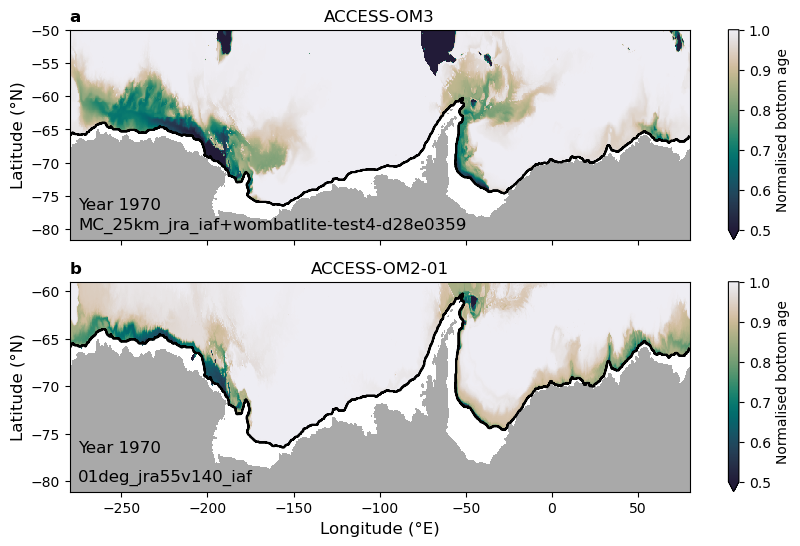

In [21]:
plt.figure(figsize=(10, 6))

plt.subplot(211)
land.plot.contourf(colors="darkgrey", add_colorbar=False)
age_bot_masked_OM3.plot(cmap=cm.cm.rain_r, vmin=0.5, vmax=1, cbar_kwargs={'label': "Normalised bottom age"})
slope_contour.fillna(2).plot.contour(levels=[0,1], colors='black', linewidths=1.5)
plt.title(model_name), plt.title('a', fontweight='bold', fontsize=ft_size, loc='left')
plt.tick_params(labelbottom=False)
plt.xlabel(''), plt.ylabel('Latitude (°N)', fontsize=ft_size)
plt.text(-275, -77, 'Year '+dates[0:4], fontsize=ft_size)
plt.text(-275, -80, get_exptname_from_path(esm_file), fontsize=ft_size)

plt.subplot(212)
land.plot.contourf(colors="darkgrey", add_colorbar=False)
age_bot_masked_OM2_01.plot(cmap=cm.cm.rain_r, vmin=0.5, vmax=1, cbar_kwargs={'label': "Normalised bottom age"})
slope_contour.fillna(2).plot.contour(levels=[0,1], colors='black', linewidths=1.5)
plt.title('ACCESS-OM2-01'), plt.title('b', fontweight='bold', fontsize=ft_size, loc='left')
plt.xlabel('Longitude (°E)', fontsize=ft_size), plt.ylabel('Latitude (°N)', fontsize=ft_size)
plt.text(-275, -77, 'Year '+dates[0:4], fontsize=ft_size)
plt.text(-275, -80, expt_01, fontsize=ft_size)

mkmd.savefig(plt.gcf(),"Bottom age tracer", "Normalised bottom age comparing ACCESS-OM3 and ACCESS-OM2 at year "+dates[0:4] , dpi=150)